        # Cognitive Science (1204 427) — Lab 10
        ## Reinforcement Learning and the Multi-Armed Bandit

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib`

        ### แนวคิดสำคัญ

        Multi-Armed Bandit แสดงปัญหา Exploration–Exploitation: ผู้เรียนต้องเลือกว่าจะทดลองทางเลือกที่ยังไม่รู้จักหรือใช้ทางเลือกที่ดูดีที่สุดในปัจจุบัน

        ### วัตถุประสงค์

        จำลอง Agent หลายกลยุทธ์ เปรียบเทียบ Reward และ Pseudo-regret และเชื่อมโยงกับการเรียนรู้จากผลตอบแทนของมนุษย์

        ### งานที่ต้องทำ

        1. สร้าง Bandit Environment ที่มี 4 Arms
2. ทดลอง Greedy และ Epsilon-greedy หลายค่า
3. สร้าง UCB Agent
4. เปรียบเทียบ Cumulative Reward และ Pseudo-regret หลายรอบจำลอง
5. Required Extension: หา epsilon ที่เหมาะสมจาก Candidate Grid

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_rng = np.random.default_rng(seed + 100)
arm_probabilities = np.sort(base_rng.uniform(0.20, 0.80, 4))
print("Hidden reward probabilities:", arm_probabilities.round(3))

def run_agent(policy, rounds=500, run_seed=0, epsilon=0.1):
    rng = np.random.default_rng(run_seed)
    counts = np.zeros(len(arm_probabilities)); values = np.zeros(len(arm_probabilities))
    rewards = []; pseudo_regret = []
    best_p = arm_probabilities.max()
    for t in range(1, rounds + 1):
        if policy == "epsilon_greedy":
            if rng.random() < epsilon or counts.sum() == 0:
                arm = rng.integers(len(values))
            else:
                arm = int(np.argmax(values))
        elif policy == "ucb":
            unseen = np.where(counts == 0)[0]
            if len(unseen):
                arm = int(unseen[0])
            else:
                score = values + np.sqrt(2 * np.log(t) / counts)
                arm = int(np.argmax(score))
        else:
            raise ValueError("Unknown policy")
        reward = rng.binomial(1, arm_probabilities[arm])
        counts[arm] += 1
        values[arm] += (reward - values[arm]) / counts[arm]
        rewards.append(reward)
        pseudo_regret.append(best_p - arm_probabilities[arm])
    return np.cumsum(rewards), np.cumsum(pseudo_regret)


Hidden reward probabilities: [0.313 0.314 0.322 0.695]


In [3]:
strategies = [("Greedy", "epsilon_greedy", 0.0), ("Epsilon 0.1", "epsilon_greedy", 0.1), ("Epsilon 0.3", "epsilon_greedy", 0.3), ("UCB", "ucb", 0.0)]
rows = []
curves = {}
for name, policy, epsilon in strategies:
    reward_runs = []; regret_runs = []
    for repeat in range(80):
        rewards, regret = run_agent(policy, run_seed=seed * 1000 + repeat, epsilon=epsilon)
        reward_runs.append(rewards); regret_runs.append(regret)
    curves[name] = (np.mean(reward_runs, axis=0), np.mean(regret_runs, axis=0))
    rows.append([name, curves[name][0][-1], curves[name][1][-1]])
bandit_summary = pd.DataFrame(rows, columns=["strategy", "mean_final_reward", "mean_final_pseudo_regret"])
display(bandit_summary.round(3))


,strategy,mean_final_reward,mean_final_pseudo_regret
0,Greedy,180.588,166.451
1,Epsilon 0.1,312.862,36.416
2,Epsilon 0.3,299.388,47.616
3,UCB,301.262,45.574


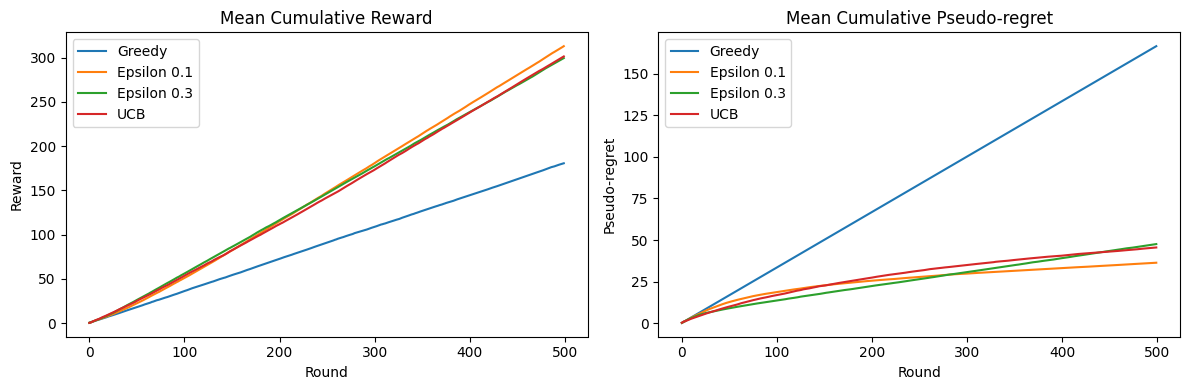

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (reward_curve, regret_curve) in curves.items():
    axes[0].plot(reward_curve, label=name); axes[1].plot(regret_curve, label=name)
axes[0].set_title("Mean Cumulative Reward"); axes[0].set_xlabel("Round"); axes[0].set_ylabel("Reward")
axes[1].set_title("Mean Cumulative Pseudo-regret"); axes[1].set_xlabel("Round"); axes[1].set_ylabel("Pseudo-regret")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()


## Required Extension

ทดลอง Epsilon ตั้งแต่ 0.00 ถึง 0.50 เพิ่มครั้งละ 0.05 โดยใช้จำนวนรอบและจำนวน Repeats เท่ากัน แล้วหาค่าที่ให้ Mean Final Pseudo-regret ต่ำที่สุด


,epsilon,mean_final_pseudo_regret
0,0.00,166.45
1,0.05,55.92
2,0.10,36.42
3,0.15,38.29
4,0.20,38.24
5,0.25,42.42
6,0.30,47.62
7,0.35,54.01
8,0.40,60.74
9,0.45,67.75


Epsilon ที่ดีที่สุด = 0.10 (mean final pseudo-regret = 36.42)


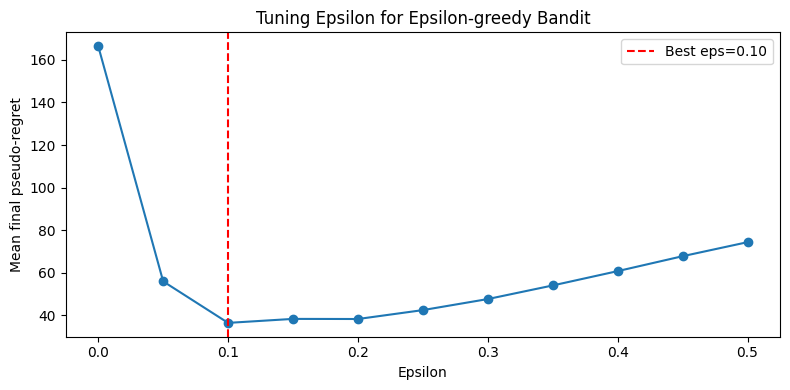

In [5]:
# ===== Required Extension: หา Epsilon ที่ให้ Pseudo-regret ต่ำสุด =====
epsilon_grid = np.arange(0.0, 0.51, 0.05)
grid_rows = []
for eps in epsilon_grid:
    finals = [run_agent("epsilon_greedy", run_seed=seed * 1000 + repeat, epsilon=eps)[1][-1]
              for repeat in range(80)]
    grid_rows.append([round(eps, 2), np.mean(finals)])

epsilon_grid_results = pd.DataFrame(grid_rows, columns=["epsilon", "mean_final_pseudo_regret"])
best_row = epsilon_grid_results.loc[epsilon_grid_results["mean_final_pseudo_regret"].idxmin()]
display(epsilon_grid_results.round(2))
print(f"Epsilon ที่ดีที่สุด = {best_row['epsilon']:.2f} (mean final pseudo-regret = {best_row['mean_final_pseudo_regret']:.2f})")

plt.figure(figsize=(8, 4))
plt.plot(epsilon_grid_results["epsilon"], epsilon_grid_results["mean_final_pseudo_regret"], marker="o")
plt.axvline(best_row["epsilon"], color="red", linestyle="--", label=f"Best eps={best_row['epsilon']:.2f}")
plt.xlabel("Epsilon")
plt.ylabel("Mean final pseudo-regret")
plt.title("Tuning Epsilon for Epsilon-greedy Bandit")
plt.legend()
plt.tight_layout()
plt.show()


## คำถามวิเคราะห์ Lab 10

**1. กลยุทธ์ใดให้ Reward สูงและ Regret ต่ำที่สุด**

Epsilon 0.1 ดีที่สุดครับ ได้ reward สะสมสูงสุด (~313) และ regret ต่ำสุด (~36) ตามด้วย UCB (~301, regret ~46) ส่วน Greedy แย่สุด (reward ~181, regret ~166) เพราะไม่ยอม explore

**2. เหตุใด Greedy จึงอาจติดอยู่กับทางเลือกที่ไม่ดีที่สุด**

เพราะ Greedy เลือกตัวที่ค่าประมาณดีที่สุดตอนนั้นตลอด ถ้าช่วงแรกบังเอิญ arm ที่ดีจริงให้รางวัลไม่ดี มันจะเลิกลองแล้วติดอยู่กับ arm ห่วยตลอดไป ไม่มีการสำรวจเพื่อแก้ค่าประมาณที่ผิด

**3. Epsilon สูงเกินไปหรือต่ำเกินไปมีผลอย่างไร**

ต่ำไป (เช่น 0) = explore น้อย เสี่ยงติด arm ผิดแบบ greedy สูงไป (เช่น 0.5) = สุ่มมั่วบ่อยเกิน เสีย reward กับ arm ที่รู้แล้วว่าแย่ จาก extension จุดที่ดีสุดอยู่ราว eps ≈ 0.10 คือ explore พอประมาณ

**4. UCB ใช้ Uncertainty เพื่อ Exploration อย่างไร**

UCB บวกโบนัสให้ arm ที่ยังลองน้อย (ค่าความไม่แน่นอนสูง) เลยได้ลองของที่ยังไม่รู้จักโดยไม่ต้องสุ่มมั่ว พอลองมากขึ้นโบนัสลด มันเลย explore แบบมีทิศทาง ฉลาดกว่า epsilon-greedy ที่สุ่มมั่ว

**5. Bandit Model คล้ายและต่างจากการเรียนรู้ของมนุษย์อย่างไร**

คล้ายตรงที่คนก็ต้องชั่งใจระหว่างลองของใหม่กับใช้ของที่รู้ว่าดี (explore-exploit) และเรียนรู้จากรางวัล แต่ต่างตรงที่คนมีอารมณ์ ความจำจำกัด ความเบื่อ และใช้บริบท/เหตุผลช่วย ไม่ได้อัปเดตค่าแบบสูตรเป๊ะๆ เหมือน agent

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอนไล่ epsilon grid เพราะต้องรัน agent ซ้ำ 80 รอบต่อค่า ทำให้ต้องระวังใช้ run_seed ให้ตรงกับของเดิมและรอโค้ดรันนานหน่อย พอได้กราฟออกมาเห็นจุดต่ำสุดชัดที่ราว 0.1 ก็หายงง

สิ่งที่เข้าใจมากขึ้นคือปัญหา explore-exploit มันจริงมาก Greedy ที่ไม่ยอมลองของใหม่เลยแพร่หลุดง่ายมาก ส่วนการ explore นิดหน่อย (eps 0.1) หรือ explore แบบมีทิศทาง (UCB) ชนะขาด ทำให้เข้าใจว่าทำไมการยอมเสี่ยงลองบ้างถึงสำคัญต่อการเรียนรู้ของทั้ง AI และคน

ถ้าทำซ้ำ อยากลอง arm ที่ค่ารางวัลเปลี่ยนตามเวลา (non-stationary) เพื่อดูว่ากลยุทธ์ไหนปรับตัวได้ดีกว่า และลองเพิ่มจำนวน arm ให้ยากขึ้น

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
